<a href="https://colab.research.google.com/github/ishikabeniwal/CSET343/blob/main/Assignment10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install wfdb tensorflow numpy scipy matplotlib scikit-learn

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import wfdb

from scipy.signal import butter, filtfilt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [3]:
DATA_DIR = "mitdb"

os.makedirs(DATA_DIR, exist_ok=True)

wfdb.dl_database("mitdb", dl_dir=DATA_DIR)

print("Dataset downloaded successfully!")

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

Sampling Frequency: 360
Signal Shape: (650000,)


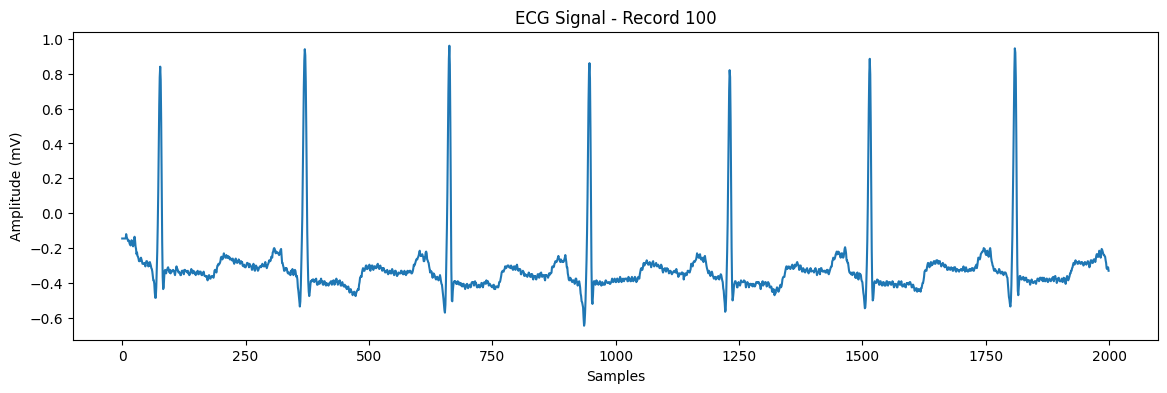

In [4]:
#Explore ECG signal
record = wfdb.rdrecord(os.path.join(DATA_DIR, "100"))

signal = record.p_signal[:, 0]

fs = record.fs

print("Sampling Frequency:", fs)
print("Signal Shape:", signal.shape)

plt.figure(figsize=(14, 4))

plt.plot(signal[:2000])

plt.title("ECG Signal - Record 100")
plt.xlabel("Samples")
plt.ylabel("Amplitude (mV)")

plt.show()

In [5]:
#Remove noise using a bandpass filter
def filter_ecg(signal, fs):

    low = 0.5
    high = 40

    nyquist = fs / 2

    b, a = butter(
        4,
        [low / nyquist, high / nyquist],
        btype='band'
    )

    filtered = filtfilt(b, a, signal)

    return filtered

In [6]:
# AAMI class mapping

aami_classes = {
    'N': ['N', 'L', 'R', 'e', 'j'],
    'S': ['A', 'a', 'J', 'S'],
    'V': ['V', 'E'],
    'F': ['F'],
    'Q': ['/', 'f', 'Q']
}

symbol_to_class = {}

for class_name, symbols in aami_classes.items():

    for symbol in symbols:
        symbol_to_class[symbol] = class_name


def extract_beats(signal, annotation, fs):

    beats = []
    labels = []

    before = int(0.2 * fs)
    after = int(0.4 * fs)

    for sample, symbol in zip(
        annotation.sample,
        annotation.symbol
    ):

        if symbol not in symbol_to_class:
            continue

        start = sample - before
        end = sample + after

        if start < 0 or end > len(signal):
            continue

        beat = signal[start:end]

        beats.append(beat)

        labels.append(symbol_to_class[symbol])

    return beats, labels

In [7]:
#Load and preprocess all recordings
records = wfdb.get_record_list("mitdb")

paced_records = {"102", "104", "107", "217"}

X = []
y = []
groups = []

for record_name in records:

    if record_name in paced_records:
        continue

    record_path = os.path.join(DATA_DIR, record_name)

    # Read ECG signal
    record = wfdb.rdrecord(record_path)

    signal = record.p_signal[:, 0]

    # Filter signal
    filtered_signal = filter_ecg(signal, record.fs)

    # Read beat annotations
    annotation = wfdb.rdann(record_path, "atr")

    # Extract beats
    beats, labels = extract_beats(
        filtered_signal,
        annotation,
        record.fs
    )

    X.extend(beats)
    y.extend(labels)

    groups.extend([record_name] * len(beats))

    print(record_name, ":", len(beats), "beats")

X = np.array(X, dtype=np.float32)

y = np.array(y)

groups = np.array(groups)

print("Total beats:", len(X))
print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)

100 : 2272 beats
101 : 1865 beats
103 : 2083 beats
105 : 2572 beats
106 : 2027 beats
108 : 1763 beats
109 : 2531 beats
111 : 2124 beats
112 : 2538 beats
113 : 1794 beats
114 : 1879 beats
115 : 1952 beats
116 : 2411 beats
117 : 1534 beats
118 : 2277 beats
119 : 1987 beats
121 : 1862 beats
122 : 2475 beats
123 : 1517 beats
124 : 1618 beats
200 : 2600 beats
201 : 1963 beats
202 : 2135 beats
203 : 2980 beats
205 : 2655 beats
207 : 1859 beats
208 : 2953 beats
209 : 3004 beats
210 : 2648 beats
212 : 2747 beats
213 : 3250 beats
214 : 2260 beats
215 : 3362 beats
219 : 2154 beats
220 : 2046 beats
221 : 2427 beats
222 : 2482 beats
223 : 2605 beats
228 : 2053 beats
230 : 2256 beats
231 : 1570 beats
232 : 1780 beats
233 : 3077 beats
234 : 2753 beats
Total beats: 100700
Dataset shape: (100700, 216)
Labels shape: (100700,)


In [8]:
#Normalize the data
mean = X.mean(axis=1, keepdims=True)

std = X.std(axis=1, keepdims=True)

X = (X - mean) / (std + 1e-8)

# Add feature dimension for RNN models

X = X[..., np.newaxis]

print("Final shape:", X.shape)

Final shape: (100700, 216, 1)


In [9]:
#Encode labels and split dataset
encoder = LabelEncoder()

y_encoded = encoder.fit_transform(y)

print("Classes:", encoder.classes_)

Classes: ['F' 'N' 'Q' 'S' 'V']


In [10]:
patient_groups = groups.copy()

patient_groups[np.isin(
    groups, ["201", "202"]
)] = "201_202"

# First split: training and temporary data

split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(X, y_encoded, groups=patient_groups)
)

# Second split: validation and testing

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_relative, test_relative = next(
    split2.split(
        X[temp_idx],
        y_encoded[temp_idx],
        groups=patient_groups[temp_idx]
    )
)

val_idx = temp_idx[val_relative]
test_idx = temp_idx[test_relative]

X_train, y_train = X[train_idx], y_encoded[train_idx]

X_val, y_val = X[val_idx], y_encoded[val_idx]

X_test, y_test = X[test_idx], y_encoded[test_idx]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (69144, 216, 1)
Validation: (14725, 216, 1)
Testing: (16831, 216, 1)


In [11]:
#Handle class imbalance
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print(class_weights)

{np.int64(0): np.float64(34.314640198511164), np.int64(1): np.float64(0.22069581870411745), np.int64(2): np.float64(1728.6), np.int64(3): np.float64(5.387144526684846), np.int64(4): np.float64(3.9443240159726183)}


In [12]:
def create_rnn():

    model = Sequential([
        SimpleRNN(64, input_shape=(216, 1)),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dense(len(encoder.classes_), activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [13]:
def create_lstm():

    model = Sequential([
        LSTM(64, input_shape=(216, 1)),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dense(len(encoder.classes_), activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [14]:
def create_gru():

    model = Sequential([
        GRU(64, input_shape=(216, 1)),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dense(len(encoder.classes_), activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [15]:
#Train all three models
models = {
    "RNN": create_rnn(),
    "LSTM": create_lstm(),
    "GRU": create_gru()
}

histories = {}

for name, model in models.items():

    print("\nTraining", name)

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=20,
        batch_size=128,
        class_weight=class_weights,
        callbacks=[early_stop],
        verbose=1
    )

    histories[name] = history

    model.save(name.lower() + "_model.keras")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Training RNN
Epoch 1/20
541/541 ━━━━━━━━━━━━━━━━━━━━ 44s 73ms/step - accuracy: 0.2888 - loss: 1.7453 - val_accuracy: 0.0017 - val_loss: 2.0671
Epoch 2/20
541/541 ━━━━━━━━━━━━━━━━━━━━ 51s 92ms/step - accuracy: 0.2245 - loss: 1.8423 - val_accuracy: 0.1264 - val_loss: 1.5485
Epoch 3/20
541/541 ━━━━━━━━━━━━━━━━━━━━ 34s 63ms/step - accuracy: 0.1696 - loss: 1.5362 - val_accuracy: 0.1552 - val_loss: 1.8094
Epoch 4/20
541/541 ━━━━━━━━━━━━━━━━━━━━ 46s 85ms/step - accuracy: 0.1777 - loss: 1.6756 - val_accuracy: 0.5172 - val_loss: 1.4363
Epoch 5/20
541/541 ━━━━━━━━━━━━━━━━━━━━ 84s 89ms/step - accuracy: 0.2478 - loss: 1.8316 - val_accuracy: 0.2143 - val_loss: 1.6291
Epoch 6/20
541/541 ━━━━━━━━━━━━━━━━━━━━ 40s 73ms/step - accuracy: 0.1996 - loss: 1.7611 - val_accuracy: 0.7267 - val_loss: 1.3636
Epoch 7/20
541/541 ━━━━━━━━━━━━━━━━━━━━ 43s 80ms/step - accuracy: 0.2020 - loss: 1.7929 - val_accuracy: 0.8424 - val_loss: 1.4313
Epoch 8/20
541/541 ━━━━━━━━━━━━━━━━━━━━ 87s 90ms/step - accuracy: 0.2084 - l

In [16]:
#Evaluate model performance
results = {}

for name, model in models.items():

    predictions = model.predict(X_test)

    predicted_classes = np.argmax(
        predictions, axis=1
    )

    accuracy = accuracy_score(
        y_test, predicted_classes
    )

    precision = precision_score(
        y_test,
        predicted_classes,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predicted_classes,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predicted_classes,
        average='macro',
        zero_division=0
    )

    results[name] = [
        accuracy,
        precision,
        recall,
        f1
    ]

    print("\n", name)

    print(classification_report(
        y_test,
        predicted_classes,
        labels=np.arange(len(encoder.classes_)),
        target_names=encoder.classes_,
        zero_division=0
    ))

526/526 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step

 RNN
              precision    recall  f1-score   support

           F       0.00      0.33      0.00         3
           N       0.87      0.72      0.79     14979
           Q       0.01      0.40      0.02         5
           S       0.06      0.71      0.12       113
           V       0.05      0.03      0.04      1731

    accuracy                           0.65     16831
   macro avg       0.20      0.44      0.19     16831
weighted avg       0.78      0.65      0.71     16831

526/526 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step

 LSTM
              precision    recall  f1-score   support

           F       0.00      0.67      0.00         3
           N       0.91      0.64      0.75     14979
           Q       0.00      0.20      0.00         5
           S       0.00      0.00      0.00       113
           V       0.11      0.01      0.03      1731

    accuracy                           0.57     16831
   macro avg       0.21      0.30

In [17]:
#Compare performance
import pandas as pd

comparison = pd.DataFrame(
    results,
    index=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

print(comparison)

                RNN      LSTM       GRU
Accuracy   0.646486  0.572456  0.528727
Precision  0.198101  0.205845  0.243310
Recall     0.438464  0.304495  0.360064
F1 Score   0.191873  0.156280  0.191680


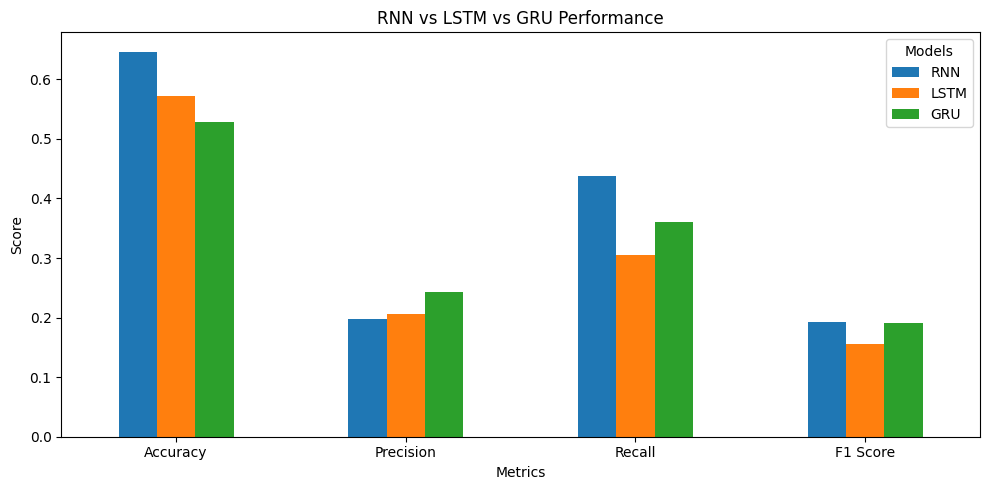

In [18]:
#Visualize the comparison:
comparison.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("RNN vs LSTM vs GRU Performance")

plt.ylabel("Score")

plt.xlabel("Metrics")

plt.xticks(rotation=0)

plt.legend(title="Models")

plt.tight_layout()

plt.show()

526/526 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step


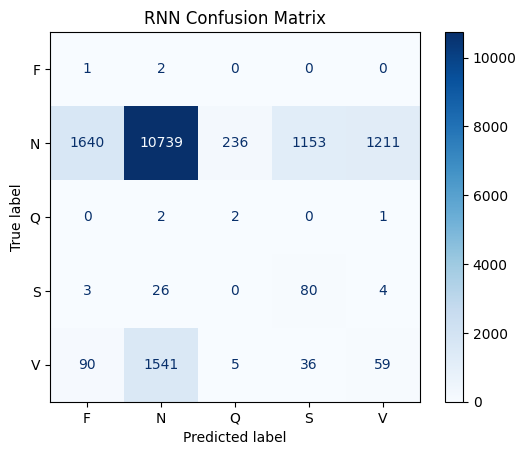

526/526 ━━━━━━━━━━━━━━━━━━━━ 19s 35ms/step


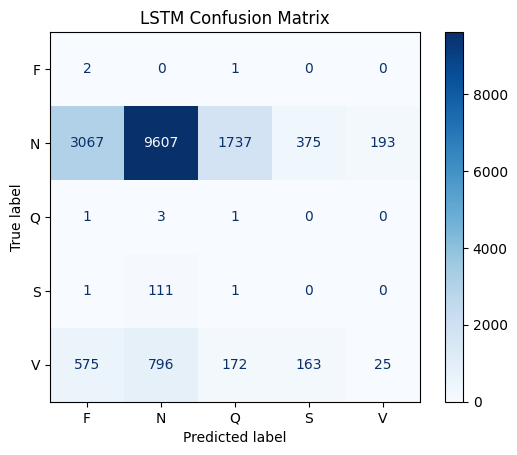

526/526 ━━━━━━━━━━━━━━━━━━━━ 34s 64ms/step


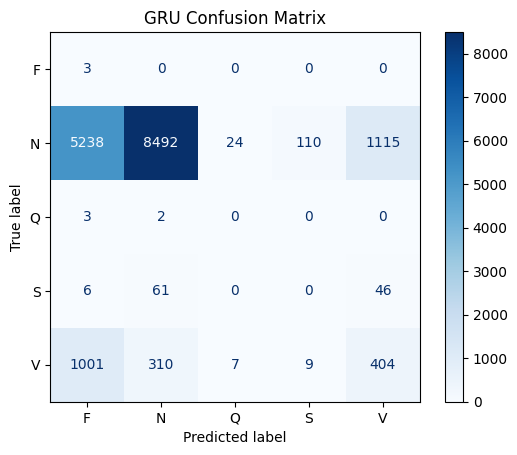

In [19]:
#Confusion matrix
for name, model in models.items():

    predictions = model.predict(X_test)

    predicted_classes = np.argmax(
        predictions, axis=1
    )

    cm = confusion_matrix(
        y_test,
        predicted_classes,
        labels=np.arange(len(encoder.classes_))
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=encoder.classes_
    )

    display.plot(cmap='Blues')

    plt.title(name + " Confusion Matrix")

    plt.show()